In [91]:
import pandas as pd
import numpy as np
import  matplotlib.pyplot as plt
import glob
import os
import cmath 
import json
import seaborn as sns
from collections import Counter
from scipy.stats import linregress


## **Data Loading**

| Subject | ID |
|----|----|
| 0 | IM0905 |
| 1 | EPC1003  |
| 2 | MN1204 |
| 3 | LL1910 |
| 4 | VD0204 (didn't do MEG)|
| 5 | LL1311 |
| 6 | IM0704 |
| 7 | AP0106 |
| 8 | LG2508 |
| 9 | RR0307 |
| 10 | SB0409 |
| 11 | LM1911 |
| 12 | AD1307 |

In [92]:
# Variables to change
pick_task = ["ENS", "MEG"]
task = "MEG"

ID = "RD2502"
subject = 14
block = 1

In [93]:
if task == "ENS" : 
    data = pd.read_csv(f"/Users/elodiehusson/Desktop/Projet/Comportement ENS/fichiers csv participants/Comportement_FRINT_ENS_num{subject}_{ID}.csv", index_col=2)
elif task == "MEG" :
    data = pd.read_csv(f"/Users/elodiehusson/Desktop/Projet/Tâche MEG/Data comportement/data clean behavior MEG/FRINT_MEG_S{subject}.csv", index_col = 0)
    metas = pd.read_csv(f"/Users/elodiehusson/Desktop/Projet/Comportement ENS/fichiers csv participants/Comportement_FRINT_ENS_num{subject}_{ID}.csv", index_col=2)
    # events = pd.read_csv(f"events MEG/events_S{subject}_B{block}.csv", index_col = 0)
    # print(events)
data

,rotangle_1,rotangle_2,rotangle_3,rotangle_4,rotangle_5,rotangle_6,rotangle_7,presangle_1,presangle_2,presangle_3,...,rotations_6,rotations_7,target,presavg,optimal,GenMean,Block,Seqlen,final_angle,trial_rt
Var1,,,,,,,,,,,,,,,,,,,,,
0,129.085891,146.708677,164.218773,126.449519,141.005917,155.228557,142.963981,174.085891,191.708677,164.218773,...,0.0,0.0,143.604207,169.555244,143.604207,145.459209,1,7,147.433235,147.433235
1,127.438601,162.758634,161.203607,175.109706,128.265312,140.145890,158.170338,127.438601,117.758634,161.203607,...,0.0,45.0,150.632221,125.418618,150.632221,142.157766,1,7,135.651060,135.651060
2,35.269286,24.322446,41.372010,67.342080,57.427641,NaN,NaN,80.269286,-20.677554,41.372010,...,NaN,NaN,45.022147,97.623303,45.022147,47.672571,1,5,62.037768,62.037768
3,38.293191,NaN,NaN,NaN,NaN,NaN,NaN,83.293191,NaN,NaN,...,NaN,NaN,38.293191,83.293191,38.293191,38.921519,1,1,43.389699,43.389699
4,63.830182,54.312629,111.826200,NaN,NaN,NaN,NaN,63.830182,54.312629,66.826200,...,NaN,NaN,73.807444,61.673318,73.807444,85.692950,1,3,84.019400,84.019400
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
355,48.373766,NaN,NaN,NaN,NaN,NaN,NaN,48.373766,NaN,NaN,...,NaN,NaN,48.373766,48.373766,48.373766,38.227768,10,1,30.699723,30.699723
356,173.003408,201.433995,190.602759,NaN,NaN,NaN,NaN,128.003408,246.433995,145.602759,...,NaN,NaN,8.444846,122.200360,8.444846,175.855689,10,3,0.609507,0.609507
357,48.066868,54.947292,62.476796,67.087022,78.676725,93.959906,83.085613,3.066868,99.947292,17.476796,...,0.0,-45.0,69.649987,63.740117,69.649987,66.001647,10,7,67.833654,67.833654


## **Functions**

In [94]:
def CircularMean(a):
    if len(a)==0:
        return(np.nan)
    resulting_vector = 0
    for i in range(len(a)):
        if not  np.isnan(a[i]):
            resulting_vector+= cmath.exp(complex(0, 2*a[i]))
    return((np.angle(resulting_vector))/2)

def circular_error(a, b):
    return ((a - b + np.pi/2) % np.pi) - np.pi/2 

## **Dataframe creation for the one subject**

### dataframe in degrees

In [95]:
if task == "ENS" : 
    df_filtered = data[data["stimulus_rotations"].notna()]
    df_filtered = df_filtered.drop(columns=["rt","target", "survey_id", "time_elapsed", "internal_node_id", "success", "responses", "view_history", "response_rts", "key_press", "confidence", "correct", "trial_type", "stimulus", "failed_tuto1", "failed_tuto2", "failed_tuto3"])
    df_filtered.reset_index(drop=True, inplace=True)
    df_filtered["length of sequence"] = df_filtered["presented_angles"].apply(lambda s: len(s.split(',')) if isinstance(s, str) else 0)
    df_filtered['presented_angles'] = df_filtered['presented_angles'].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
    df_filtered['stimulus_rotations'] = df_filtered['stimulus_rotations'].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
    df_filtered['score'] = df_filtered['score'].astype(int)
    df_filtered["expected_angles"] = df_filtered.apply(lambda row : [x + y for x,y in zip(row["presented_angles"],row["stimulus_rotations"])], axis=1)

    df_filtered = df_filtered.dropna(subset=["final_angle"])

elif task == "MEG" :
    data.columns = data.columns.str.strip()
    df_filtered = data.copy()
    # Exemple: sélection des colonnes rotangle_1 à rotangle_7
    rotangle_cols = [f'rotangle_{i}' for i in range(1, 8)]
    rotation_cols = [f'rotations_{i}' for i in range(1, 8)]
    presangle_cols = [f'presangle_{i}' for i in range(1, 8)]

    df_filtered['presented_angles'] = df_filtered[presangle_cols].apply(lambda row: row.dropna().tolist(), axis=1)
    df_filtered['expected_angles'] = df_filtered[rotangle_cols].apply(lambda row: row.dropna().tolist(), axis=1)
    df_filtered['stimulus_rotations'] = df_filtered[rotation_cols].apply(lambda row: row.dropna().tolist(), axis=1)
    df_filtered["expected_angles_wo_rot"] = df_filtered["presavg"]
    df_filtered["length of sequence"] = df_filtered["Seqlen"]

    df_filtered = df_filtered.drop(columns=rotangle_cols + rotation_cols + presangle_cols)

    df_filtered = df_filtered.drop(columns=["optimal", "presavg", "Seqlen"])
    df_filtered.reset_index(drop=True, inplace=True)
    df_filtered = df_filtered.dropna(subset=["final_angle"])

### dataframe in radian

In [96]:
if task == "ENS" :
    df_radian = df_filtered.copy().drop(columns=["presented_angles", "final_angle", "expected_angles", "stimulus_rotations"])
    df_radian['final_angle'] = np.deg2rad(df_filtered['final_angle'])

    df_radian['stimulus_rotations'] = df_filtered['stimulus_rotations'].apply(
        lambda lst: np.deg2rad(np.array(lst, dtype=float)))

    df_radian['presented_angles'] = df_filtered['presented_angles'].apply(
        lambda lst: np.deg2rad(np.array(lst, dtype=float)))

    df_radian['expected_angles'] = df_filtered['expected_angles'].apply(
        lambda lst: np.deg2rad(np.array(lst, dtype=float)))

    df_radian["target"] = df_radian["expected_angles"].apply(CircularMean) 
    df_filtered["target"] = df_radian["target"].apply(np.rad2deg) 

    df_radian["mean_rotation"] = df_radian["stimulus_rotations"].apply(np.mean) 
    
elif task == "MEG" : 
    df_radian = df_filtered.copy().drop(columns=["presented_angles", "final_angle", "expected_angles", "stimulus_rotations", "GenMean", "target", "expected_angles_wo_rot"])
    df_radian['final_angle'] = np.deg2rad(df_filtered['final_angle'])
    df_radian["target"] = np.deg2rad(df_filtered['target'])
    df_radian["GenMean"] = np.deg2rad(df_filtered['GenMean'])
    df_radian["expected_angles_wo_rot"] = np.deg2rad(df_filtered['expected_angles_wo_rot'])

    df_radian['stimulus_rotations'] = df_filtered['stimulus_rotations'].apply(
        lambda lst: np.deg2rad(np.array(lst, dtype=float)))

    df_radian['presented_angles'] = df_filtered['presented_angles'].apply(
        lambda lst: np.deg2rad(np.array(lst, dtype=float)))

    df_radian['expected_angles'] = df_filtered['expected_angles'].apply(
        lambda lst: np.deg2rad(np.array(lst, dtype=float)))


    df_radian["mean_rotation"] = df_radian["stimulus_rotations"].apply(np.mean) 
    


df_radian

,Block,trial_rt,length of sequence,final_angle,target,GenMean,expected_angles_wo_rot,stimulus_rotations,presented_angles,expected_angles,mean_rotation
0,1,147.433235,7,2.573195,2.506366,2.538742,2.959297,"[-0.7853981633974483, -0.7853981633974483, 0.0...","[3.0383719799160955, 3.345947612183673, 2.8661...","[2.2529738165186473, 2.5605494487862246, 2.866...",-0.448799
1,1,135.651060,7,2.367558,2.629028,2.481121,2.188968,"[0.0, 0.7853981633974483, 0.0, 0.7853981633974...","[2.2242231829816017, 2.0552758838565452, 2.813...","[2.2242231829816017, 2.840674047253993, 2.8135...",0.448799
2,1,62.037768,5,1.082763,0.785785,0.832043,1.703848,"[-0.7853981633974483, 0.7853981633974483, 0.0,...","[1.4009633273541926, -0.3608914065874381, 0.72...","[0.6155651639567444, 0.42450675681001016, 0.72...",-0.314159
3,1,43.389699,1,0.757293,0.668342,0.679309,1.453740,[-0.7853981633974483],[1.4537404223810535],[0.668342258983605],-0.785398
4,1,84.019400,3,1.466415,1.288183,1.495624,1.076402,"[0.0, 0.0, 0.7853981633974483]","[1.114046831414968, 0.9479342100162687, 1.1663...","[1.114046831414968, 0.9479342100162687, 1.9517...",0.261799
...,...,...,...,...,...,...,...,...,...,...,...
355,10,30.699723,1,0.535811,0.844281,0.667200,0.844281,[0.0],[0.8442814968414006],[0.8442814968414006],0.000000
356,10,0.609507,3,0.010638,0.147390,3.069261,2.132799,"[0.7853981633974483, -0.7853981633974483, 0.78...","[2.234080918137662, 4.301084601767776, 2.54124...","[3.0194790815351102, 3.515686438370328, 3.3266...",0.261799
357,10,67.833654,7,1.183921,1.215622,1.151946,1.112475,"[0.7853981633974483, -0.7853981633974483, 0.78...","[0.053526942229658356, 1.7444093159982068, 0.3...","[0.8389251056271065, 0.9590111526007585, 1.090...",0.112200
358,10,22.145180,7,0.386506,0.492889,0.512730,2.978299,"[0.7853981633974483, 0.7853981633974483, -0.78...","[-0.4757239707992179, 0.005095966447813716, 1....","[0.3096741925982304, 0.790494129845262, 0.5900...",0.112200


## **Metadata Exploration**

### basic informations 

In [97]:
if task == "ENS" : 
    print(f"the participant's score is {df_radian["score"].sum()}/2000")


In [98]:
if task == "ENS" : 
    print(f"participant's gender is : {data["responses"][4][7]}")
else : 
    print(f"participant's gender is : {metas["responses"][4][7]}")

participant's gender is : M


In [99]:
if task == "ENS" : 
    print(f"participant's age is between : {data["responses"][3][7:12]}")
else : 
    print(f"participant's age is between : {metas["responses"][3][7:12]}")

participant's age is between : 32–40


### rotation proportions

In [100]:
angles_lists = df_filtered["stimulus_rotations"]
all_angles = set()
for lst in angles_lists:
    all_angles.update(lst)
angle_presence = {}
total_lists = len(angles_lists)
for angle in all_angles:
    count = sum(angle in lst for lst in angles_lists)
    angle_presence[angle] = count / total_lists * 100  # en %

print("Proportion of sequences that contain each 3 angles (%) :")
for angle, pct in angle_presence.items():
    print(f"Angle {angle}: {pct:.1f}%")
all_occurrences = [angle for lst in angles_lists for angle in lst]
freq = Counter(all_occurrences)

print("\ntotal frequency of each angle (number of occurence) :")
for angle, count in freq.items():
    print(f"Angle {angle}: {count}")



Proportion of sequences that contain each 3 angles (%) :
Angle 0.0: 67.2%
Angle -45.0: 68.1%
Angle 45.0: 68.6%

total frequency of each angle (number of occurence) :
Angle -45.0: 453
Angle 0.0: 490
Angle 45.0: 497


In [101]:
df_filtered['length_of_sequence'] = df_filtered['stimulus_rotations'].apply(len)
only_45 = df_filtered[df_filtered['stimulus_rotations'].apply(lambda x: all(angle == 45.0 for angle in x))]
only_minus45 = df_filtered[df_filtered['stimulus_rotations'].apply(lambda x: all(angle == -45.0 for angle in x))]

only_minus45_filtered = only_minus45[only_minus45['length_of_sequence'] > 1]
only_45_filtered = only_45[only_45['length_of_sequence'] > 1]

print("Sequences 100% of +45° and length > 1 :")
print("there are", len(only_45), "sequences 100% of +45° in total, and", len(only_45_filtered),"sequences of 1 element +45°")

print("\nSequences 100% of -45° and length > 1 :")
print("there are", len(only_minus45), "sequences 100% of -45° in total, and", len(only_minus45_filtered),"sequences of 1 element -45°")

Sequences 100% of +45° and length > 1 :
there are 38 sequences 100% of +45° in total, and 3 sequences of 1 element +45°

Sequences 100% of -45° and length > 1 :
there are 30 sequences 100% of -45° in total, and 8 sequences of 1 element -45°


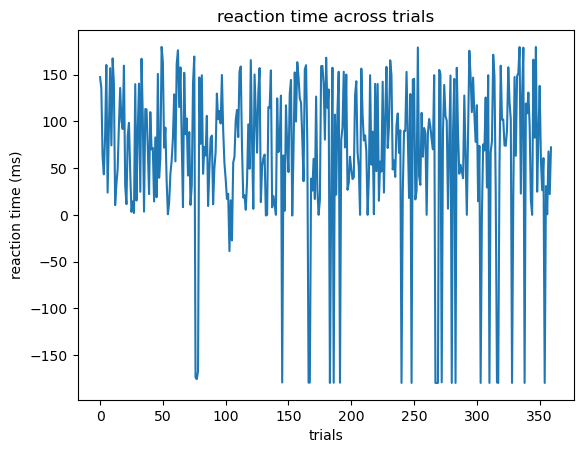

In [102]:
plt.plot(df_filtered["trial_rt"])
plt.title("reaction time across trials")
plt.xlabel("trials")
plt.ylabel("reaction time (ms)")
plt.show()

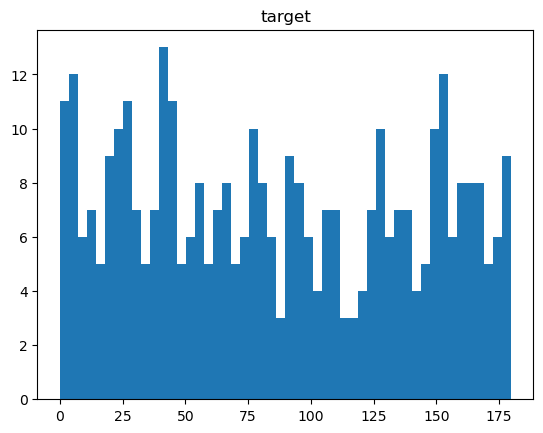

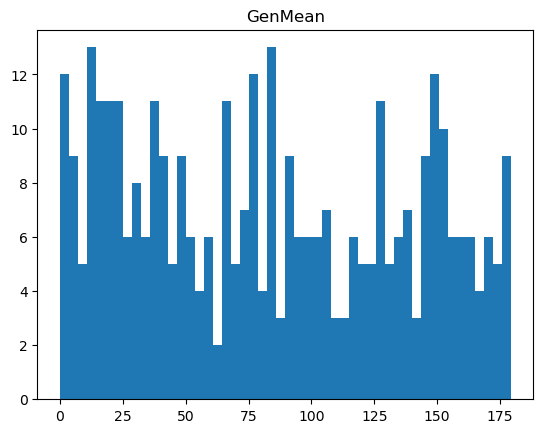

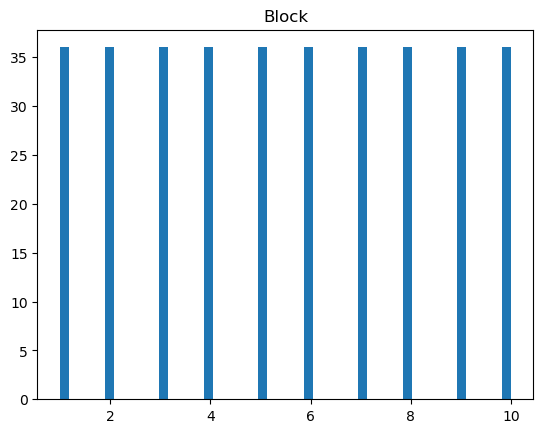

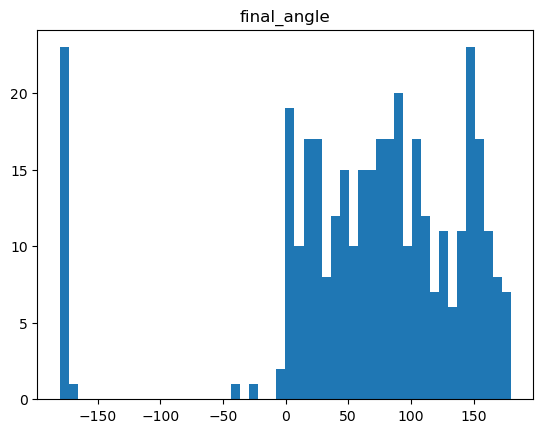

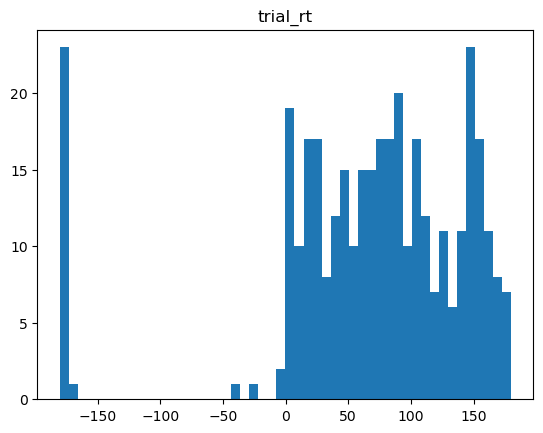

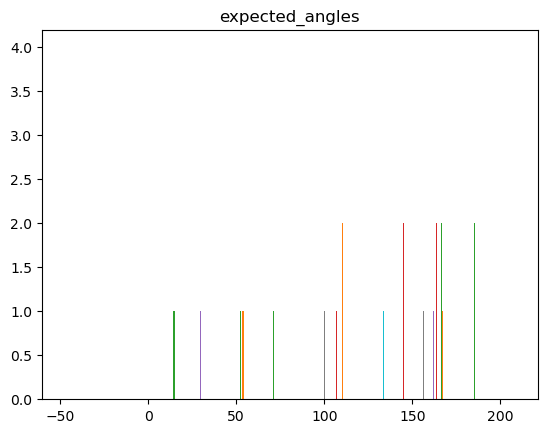

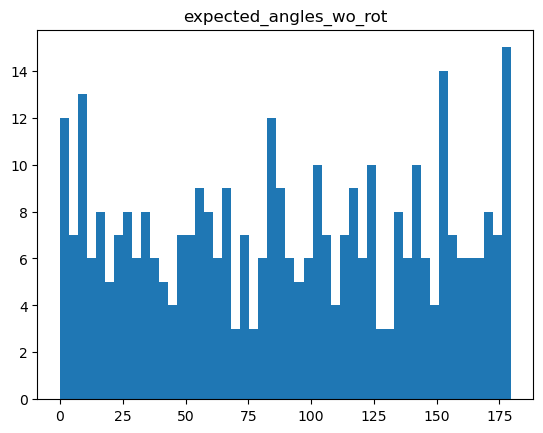

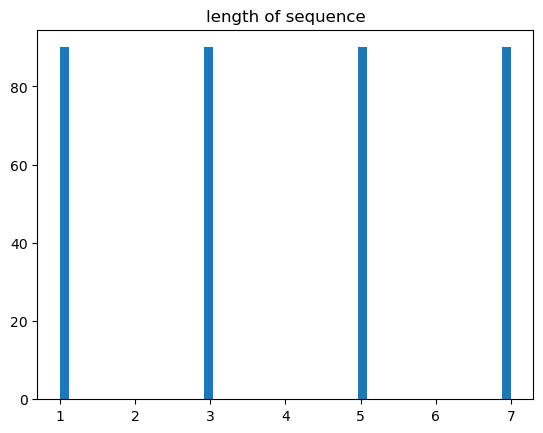

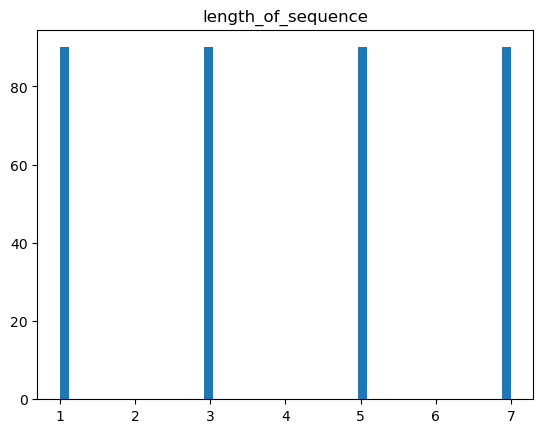

In [103]:
for column in df_filtered.columns:
    if column not in ["presented_angles", "stimulus_rotations"]:
        plt.figure()
        plt.hist(df_filtered[column], bins=50)
        plt.title(column)
        plt.show()

## **Performances**

In [104]:
df_radian["error_to_target"] = circular_error(df_radian["final_angle"], df_radian["target"]) 
df_filtered["error_to_target"] = df_radian["error_to_target"].apply(np.rad2deg)

In [105]:
conditions = [
    np.abs(df_radian["error_to_target"].apply(np.rad2deg)) < 6,
    np.abs(df_radian["error_to_target"].apply(np.rad2deg)) < 12,
    np.abs(df_radian["error_to_target"].apply(np.rad2deg)) < 18,
    np.abs(df_radian["error_to_target"].apply(np.rad2deg)) < 24,
    np.abs(df_radian["error_to_target"].apply(np.rad2deg)) < 30
]

choices = [10, 8, 6, 4, 2]

if task == "MEG" : 
    df_radian["score"] = np.select(conditions, choices, default=0)

In [106]:
if task == "MEG" : 
    print(f"the participant's score is {df_radian["score"].sum()}/3600, {df_radian["score"].sum()/3600*100:.2f}% ")

the participant's score is 2546/3600, 70.72% 


### Did the participants responded well ? (error between final angle and the target angle) 

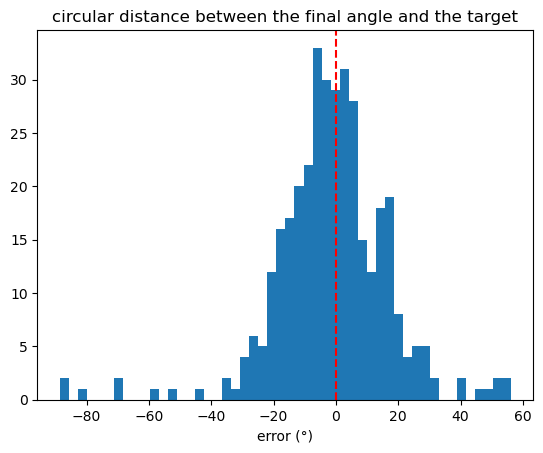

In [107]:
plt.hist(np.rad2deg(df_radian["error_to_target"]), bins=50)
plt.axvline(0, color='red', linestyle='--') 
plt.xlabel("error (°)")
plt.title("circular distance between the final angle and the target")
plt.show()

### Did the participants ignored the rotations ? (take into account only the orientations that they have seen, without rotating the stimulus)

In [108]:
df_radian["expected_angles_wo_rot"] = df_radian["presented_angles"].apply(CircularMean)
df_radian["error_wo_rotation"] = circular_error(df_radian["final_angle"], df_radian["expected_angles_wo_rot"])  

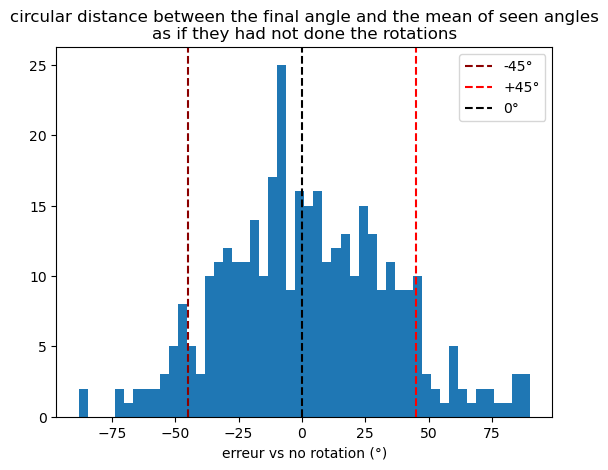

In [109]:
plt.hist(np.rad2deg(df_radian["error_wo_rotation"]), bins=50)
plt.axvline(-45, color='darkred', linestyle='--', label="-45°") 
plt.axvline(45, color='red', linestyle='--', label="+45°") 
plt.axvline(0, color='black', linestyle='--', label="0°") 

plt.xlabel("erreur vs no rotation (°)")
plt.title("circular distance between the final angle and the mean of seen angles\nas if they had not done the rotations")
plt.legend()
plt.show()

### Mean rotations VS errors

mean rotation vs error to target : the response error

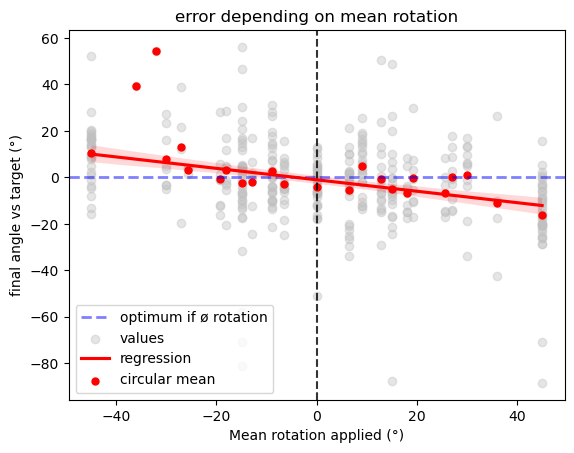

In [110]:
x = (df_radian.groupby("mean_rotation")["error_to_target"].apply(np.mean).reset_index().sort_values("mean_rotation")).apply(np.rad2deg)

plt.axvline(0, color="black", linestyle="--", alpha = 0.8)   
plt.axhline(0, color="blue", linestyle="--", label= "optimum if ø rotation", alpha = 0.5, linewidth =2)   

sns.regplot(x=df_radian["mean_rotation"].apply(np.rad2deg), y=df_radian["error_to_target"].apply(np.rad2deg), color = "silver", label = "values", scatter_kws={'alpha':0.4}, line_kws={"color":"red", "label" : "regression"})
plt.scatter(x["mean_rotation"], x["error_to_target"], color="red", s=25, label="circular mean")

plt.xlabel("Mean rotation applied (°)")
plt.ylabel("final angle vs target (°)")
plt.title("error depending on mean rotation")
plt.legend()
plt.show()

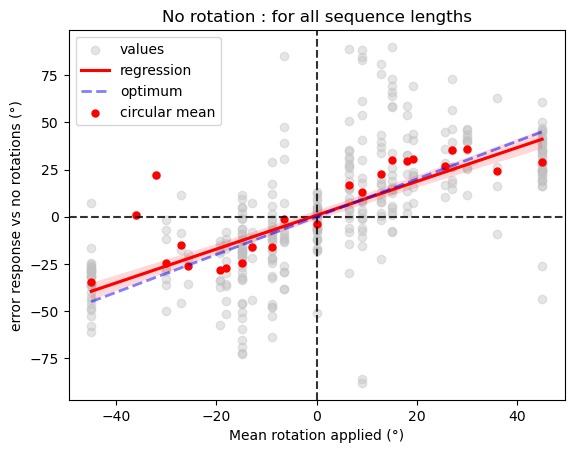

In [111]:
x = (df_radian.groupby("mean_rotation")["error_wo_rotation"].apply(np.mean).reset_index().sort_values("mean_rotation")).apply(np.rad2deg)

plt.axvline(0, color="black", linestyle="--", alpha = 0.8)   
plt.axhline(0, color="black", linestyle="--", alpha = 0.8)   

sns.regplot(x=df_radian["mean_rotation"].apply(np.rad2deg), y=df_radian["error_wo_rotation"].apply(np.rad2deg), color = "silver", label = "values", scatter_kws={'alpha':0.4}, line_kws={"color":"red", "label" : "regression"})
borne = x["mean_rotation"]
plt.plot(np.linspace(min(borne),max(borne),100),np.linspace(min(borne),max(borne),100),"--" , color = "blue",label= "optimum", alpha = 0.5, linewidth =2)
plt.scatter(x["mean_rotation"], x["error_wo_rotation"], color="red", s=25, label="circular mean")

plt.xlabel("Mean rotation applied (°)")
plt.ylabel("error response vs no rotations (°)")
plt.title("No rotation : for all sequence lengths")
plt.legend()
plt.show()

plot for different sequence lengths

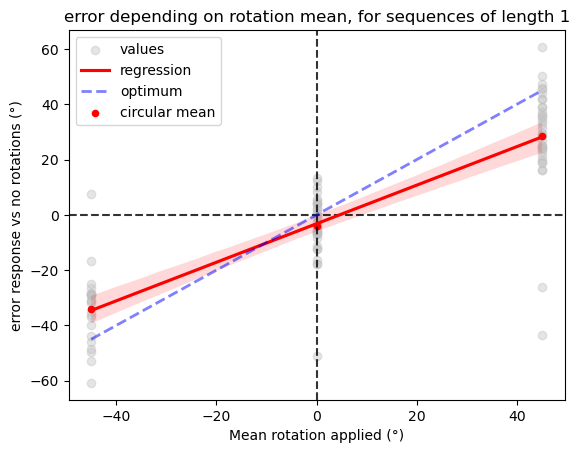

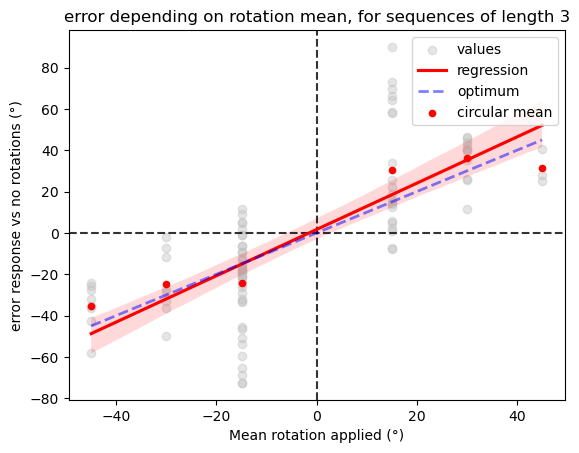

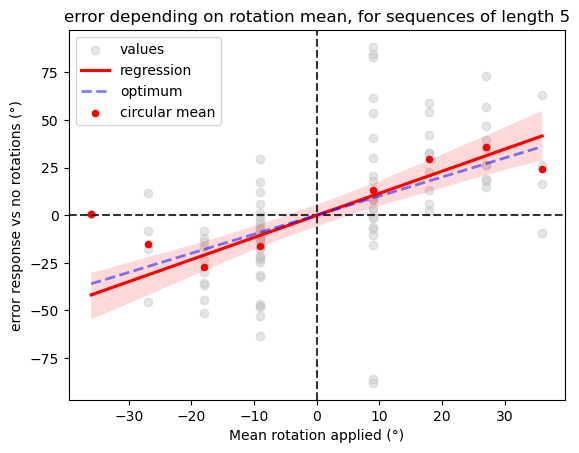

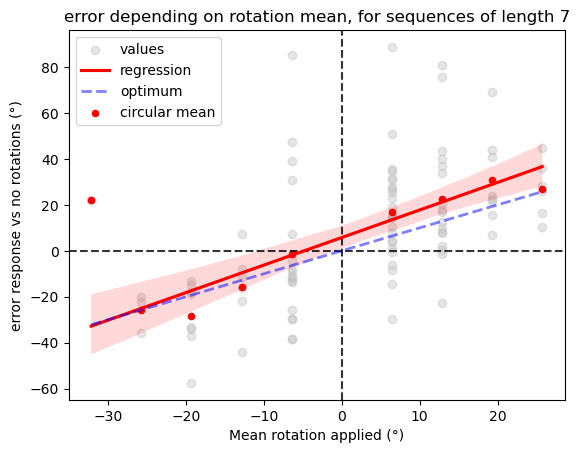

In [112]:
for seqlen in [1,3,5,7] :
    plt.figure()
    x = (df_radian[df_radian["length of sequence"]==seqlen].groupby("mean_rotation")["error_wo_rotation"].apply(np.mean).reset_index().sort_values("mean_rotation")).apply(np.rad2deg)

    plt.axvline(0, color="black", linestyle="--", alpha = 0.8)   
    plt.axhline(0, color="black", linestyle="--", alpha = 0.8)   

    borne = x["mean_rotation"]
    sns.regplot(x=df_radian[df_radian["length of sequence"]==seqlen]["mean_rotation"].apply(np.rad2deg), y=df_radian[df_radian["length of sequence"]==seqlen]["error_wo_rotation"].apply(np.rad2deg), color = "silver", label = "values", scatter_kws={'alpha':0.4}, line_kws={"color":"red", "label" : "regression"})
    plt.plot(np.linspace(min(borne),max(borne),100),np.linspace(min(borne),max(borne),100),"--" , color = "blue",label= "optimum", alpha = 0.5, linewidth =2)
    plt.scatter(x["mean_rotation"], x["error_wo_rotation"], color="red", s=20, label="circular mean")

    plt.xlabel("Mean rotation applied (°)")
    plt.ylabel("error response vs no rotations (°)")    
    plt.title(f"error depending on rotation mean, for sequences of length {seqlen}")
    plt.legend()
    plt.show()

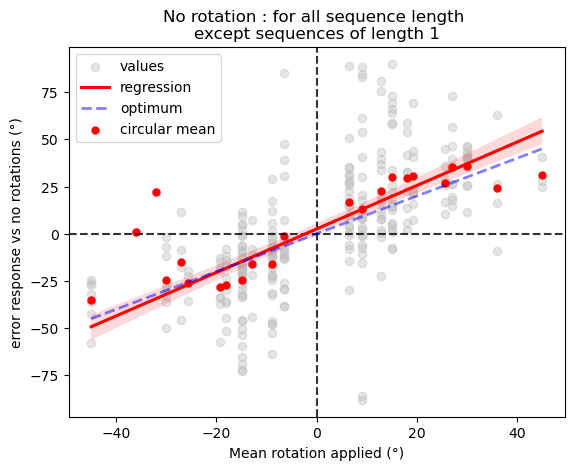

In [113]:
df = df_radian[df_radian["length of sequence"]!=1]

x = (df.groupby("mean_rotation")["error_wo_rotation"].apply(np.mean).reset_index().sort_values("mean_rotation")).apply(np.rad2deg)

plt.axvline(0, color="black", linestyle="--", alpha = 0.8)   
plt.axhline(0, color="black", linestyle="--", alpha = 0.8)   

borne = x["mean_rotation"]
sns.regplot(x=df["mean_rotation"].apply(np.rad2deg), y=df["error_wo_rotation"].apply(np.rad2deg), color = "silver", label = "values", scatter_kws={'alpha':0.4}, line_kws={"color":"red", "label" : "regression"})
plt.plot(np.linspace(min(borne),max(borne),100),np.linspace(min(borne),max(borne),100),"--" , color = "blue",label= "optimum", alpha = 0.5, linewidth =2)
plt.scatter(x["mean_rotation"], x["error_wo_rotation"], color="red", s=25, label="circular mean")

plt.xlabel("Mean rotation applied (°)")
plt.ylabel("error response vs no rotations (°)")    
plt.title("No rotation : for all sequence length \nexcept sequences of length 1")
plt.legend()
plt.show()

## **Reaction time**

### RT vs error

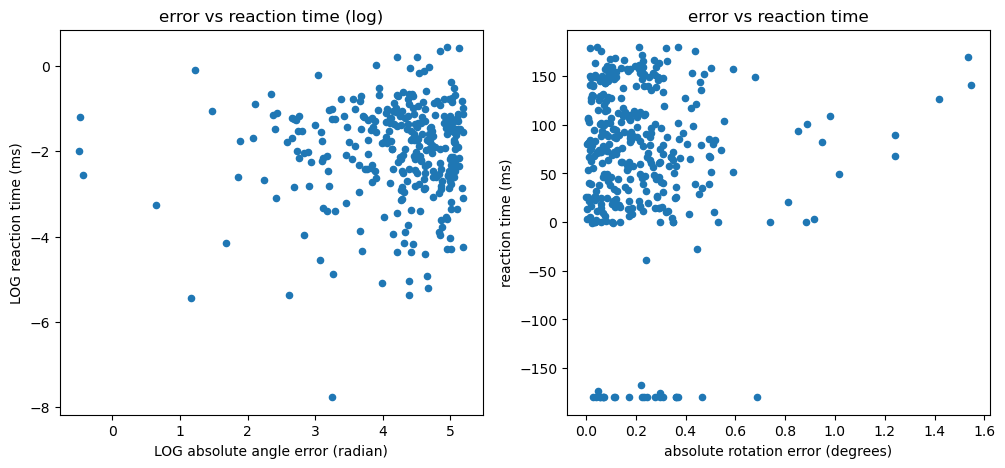

In [114]:
plt.subplots(1,2, figsize=(12,5))

plt.subplot(1,2,1) 
plt.scatter(df_radian["trial_rt"].apply(np.log), np.abs(df_radian["error_to_target"]).apply(np.log), s=20)
plt.xlabel("LOG absolute angle error (radian)")
plt.ylabel("LOG reaction time (ms)")
plt.title("error vs reaction time (log)")

plt.subplot(1,2,2) 
plt.scatter(np.abs(df_radian["error_to_target"]), df_radian["trial_rt"], s=20)
plt.xlabel("absolute rotation error (degrees)")
plt.ylabel("reaction time (ms)")
plt.title("error vs reaction time")
plt.show()

### error vs le temps

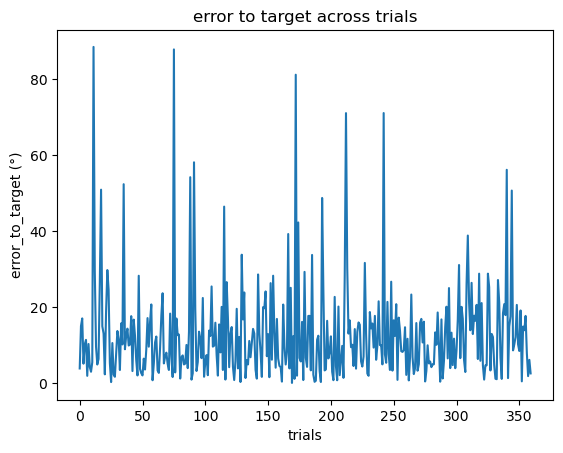

In [115]:
plt.plot(np.abs(df_radian["error_to_target"].apply(np.rad2deg)))
plt.xlabel("trials")
plt.ylabel("error_to_target (°)")
plt.title("error to target across trials")
plt.show()

### Score vs time

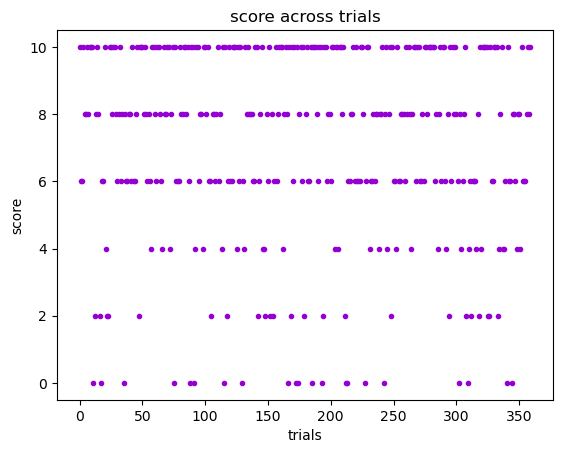

In [116]:
plt.plot(df_radian["score"], '.', color = "darkviolet")
plt.xlabel("trials")
plt.ylabel("score")
plt.title("score across trials")
plt.show()

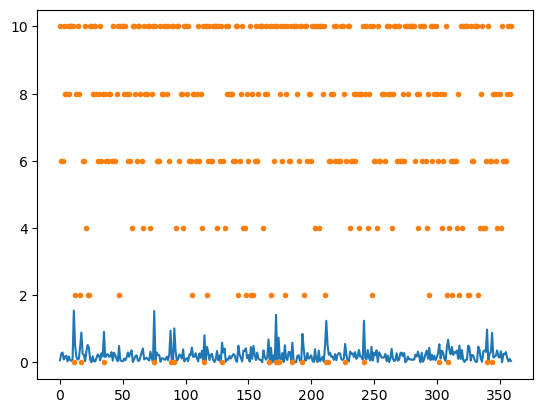

In [117]:
plt.plot(np.abs(df_radian["error_to_target"]))
plt.plot(df_radian["score"], '.')


In [118]:
filepaths = glob.glob("données/*.csv")
dfs = [pd.read_csv(f, skiprows=1, index_col=3) for f in filepaths]
filepaths_ENS = glob.glob("/Users/elodiehusson/Desktop/Projet/Comportement ENS/fichiers csv participants/*.csv")
dfs_ENS = [pd.read_csv(f, index_col=2) for f in filepaths_ENS]

    # data = pd.read_csv(f"/Users/elodiehusson/Desktop/Projet/Comportement ENS/fichiers csv participants/Comportement_FRINT_ENS_num{subject}_{ID}.csv", index_col=2)

def data_sujets (dfs) : 
    score_sum = []
    age_tot = []
    sex_tot = []
    for df in dfs :    
        survey = df[df["trial_type"] == "survey-dropdown"]
        if len(survey) == 0:
            age, sex = None, None
        else:
            resp = json.loads(survey.iloc[0]["responses"])
            age = resp.get("0")
            sex = resp.get("1")        
        age_tot.append(age)
        sex_tot.append(sex)
        
        df_filtered = df[df["stimulus_rotations"].notna()].copy()
        df_filtered = df_filtered.dropna(subset=["final_angle"]).copy()
        
        df_filtered['score'] = pd.to_numeric(df_filtered["score"], errors="coerce")
        score_sum.append(df_filtered["score"].sum(skipna=True))
        
    return score_sum, age_tot, sex_tot

def data_sujets_ENS (dfs) : 
    score_sum = []
    for df in dfs :    

        df_filtered = df[df["stimulus_rotations"].notna()].copy()
        df_filtered = df_filtered.dropna(subset=["final_angle"]).copy()
        
        df_filtered['score'] = pd.to_numeric(df_filtered["score"], errors="coerce")
        score_sum.append(df_filtered["score"].sum(skipna=True))
        
    return score_sum

if task == "ENS" :
    scores, ages, sexs = data_sujets(dfs)

    plt.hist(scores, bins=50)
    plt.axvline(df_radian["score"].sum(), color='black', linestyle='--', label = "score of participant :\n"+f"{df_radian['score'].sum()}/2000 ")
    plt.axvline(np.mean(scores), color='red', linestyle='--', label = "mean :\n"+f"{np.mean(scores):.2f}/2000 ")
    plt.title(f"score sum for all {len(scores)} subjects\nmaximum possible being 2000 (10*200 viewed elements)")
    plt.xlabel("score sum")
    plt.legend()
    # plt.savefig("/Users/elodiehusson/Desktop/Projet/Sanity check comportement code/somme des scores par sujet.pdf")
    plt.show()


if task == "ENS" :
    scores_ENS = data_sujets_ENS(dfs_ENS)

    plt.hist(scores_ENS, bins=50)
    plt.axvline(df_radian["score"].sum(), color='black', linestyle='--', label = "score of participant :\n"+f"{df_radian['score'].sum()}/2000 ")
    plt.axvline(np.mean(scores_ENS), color='red', linestyle='--', label = "mean :\n"+f"{np.mean(scores_ENS):.2f}/2000 ")
    plt.title(f"score sum for all {len(scores_ENS)} subjects\nmaximum possible being 2000 (10*200 viewed elements)")
    plt.xlabel("score sum")
    plt.legend()
    # plt.savefig("/Users/elodiehusson/Desktop/Projet/Sanity check comportement code/somme des scores par sujet.pdf")
    plt.show()

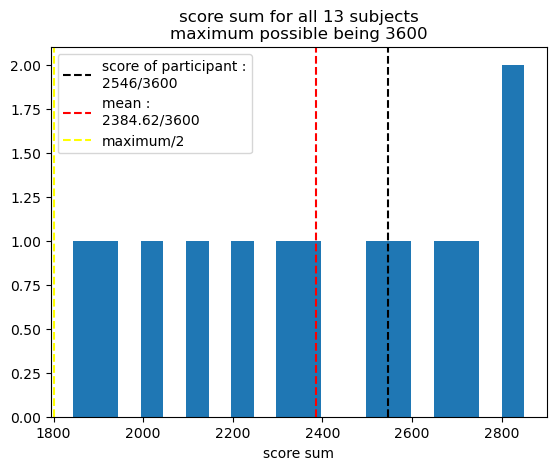

In [119]:
filepaths_MEG = glob.glob("/Users/elodiehusson/Desktop/Projet/Tâche MEG/Data comportement/data clean behavior MEG/*.csv")
dfs_MEG = [pd.read_csv(f, index_col=0) for f in filepaths_MEG]

scores_MEG = []
for df in dfs_MEG : 
    error_to_target = circular_error(np.deg2rad(df["final_angle"]), np.deg2rad(df["target"])) 
    conditions = [np.abs(error_to_target.apply(np.rad2deg)) < 6, np.abs(error_to_target.apply(np.rad2deg)) < 12, np.abs(error_to_target.apply(np.rad2deg)) < 18, np.abs(error_to_target.apply(np.rad2deg)) < 24, np.abs(error_to_target.apply(np.rad2deg)) < 30]
    scores_MEG.append(sum(np.select(conditions, choices, default=0)))

scores_MEG
if task == "MEG" :
    plt.hist(scores_MEG, bins=20)
    plt.axvline(df_radian["score"].sum(), color='black', linestyle='--', label = "score of participant :\n"+f"{df_radian['score'].sum()}/3600 ")
    plt.axvline(np.mean(scores_MEG), color='red', linestyle='--', label = "mean :\n"+f"{np.mean(scores_MEG):.2f}/3600 ")
    plt.axvline(3600/2, color='yellow', linestyle='--', label = "maximum/2")
    plt.title(f"score sum for all {len(scores_MEG)} subjects\nmaximum possible being 3600")
    plt.xlabel("score sum")
    plt.legend()
    # plt.savefig("/Users/elodiehusson/Desktop/Projet/Sanity check comportement code/somme des scores par sujet.pdf")
    plt.show()

### RT vs time

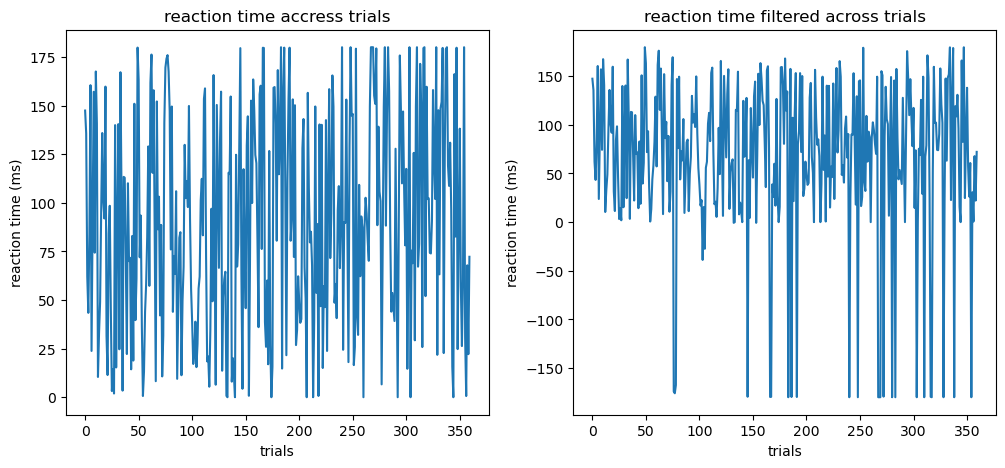

In [120]:
plt.subplots(1,2, figsize=(12,5))

plt.subplot(1,2,1) 
plt.plot(np.abs(df_radian["trial_rt"]))
plt.xlabel("trials")
plt.ylabel("reaction time (ms)")
plt.title("reaction time accress trials")

mean_rt = df_radian["trial_rt"].mean()
std_rt = df_radian["trial_rt"].std()
upper_threshold = mean_rt + 2*std_rt

rt_filtered = df_radian["trial_rt"].copy()
rt_filtered[(rt_filtered > upper_threshold)] = np.nan

plt.subplot(1,2,2)
plt.plot(rt_filtered)
plt.xlabel("trials")
plt.ylabel("reaction time (ms)")
plt.title("reaction time filtered across trials")
plt.show()

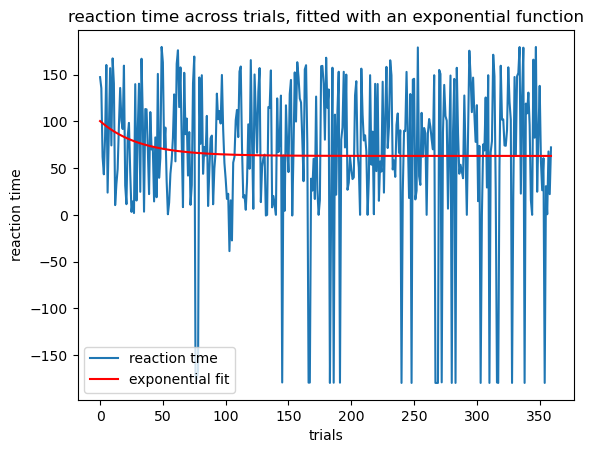

In [121]:
from scipy.optimize import curve_fit

y = rt_filtered.values.astype(float)
x = np.arange(len(y))

mask = np.isfinite(y)
x_clean = x[mask]
y_clean = y[mask]

# exponential model
def exp_model(x, a, b, c):
    return a * np.exp(-b * x) + c

# fit
params, _ = curve_fit(
    exp_model,
    x_clean,
    y_clean,
    p0=[1000, 0.01, 2000],   # best guesses
    maxfev=10000          
)

a, b, c = params

y_fit_full = exp_model(x, a, b, c)

plt.plot(x, y, label="reaction tme")
plt.plot(x, y_fit_full, "r", label="exponential fit")
plt.legend()
plt.xlabel("trials")
plt.ylabel("reaction time")
plt.title("reaction time across trials, fitted with an exponential function")
plt.show()

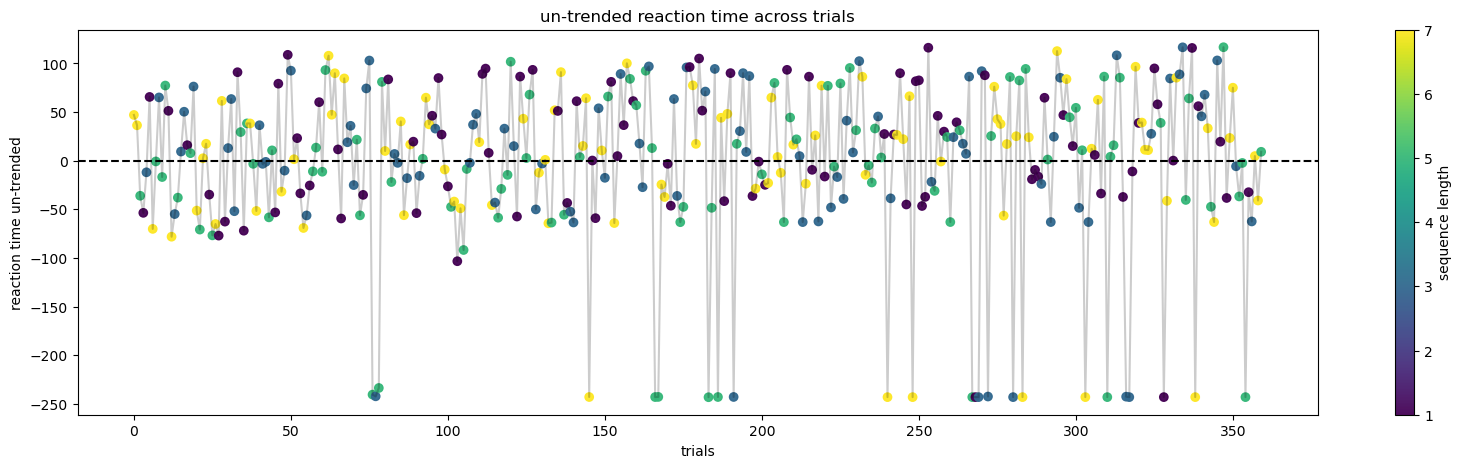

In [122]:
seq = df_radian["length of sequence"].values

plt.figure(figsize=(20,5))

residuals = y - y_fit_full
plt.plot(x, residuals, color = "black", alpha = 0.2)
plt.scatter(x, residuals, c=seq, cmap="viridis", alpha=0.95)
plt.colorbar(label="sequence length")
plt.axhline(np.mean(residuals), color="black", linestyle="--")
plt.xlabel("trials")
plt.ylabel("reaction time un-trended")
plt.title("un-trended reaction time across trials")
plt.show()


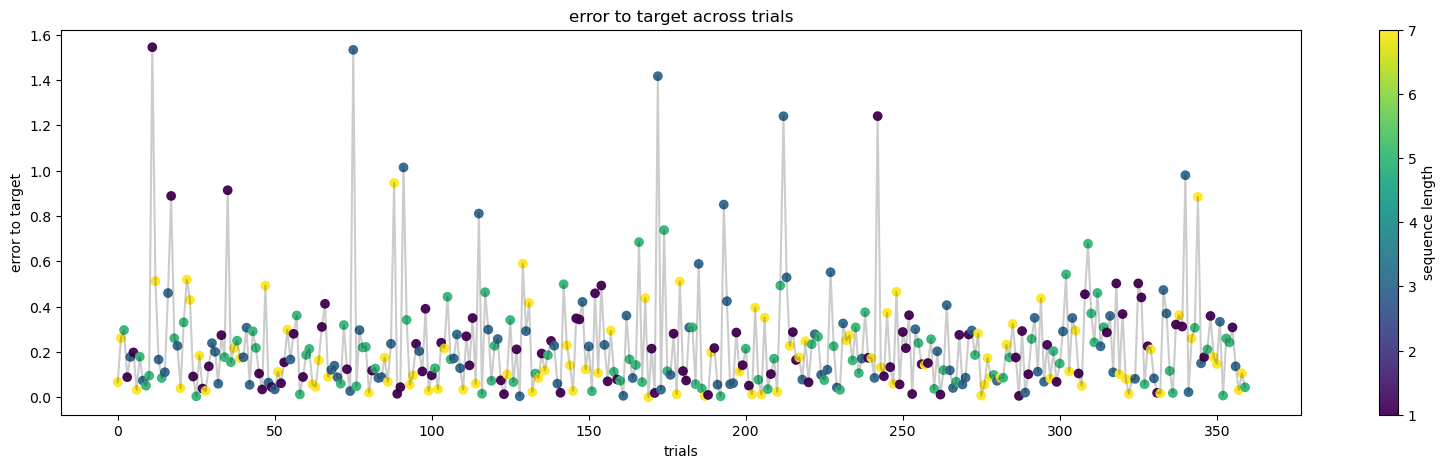

In [123]:
seq = df_radian["length of sequence"].values

plt.figure(figsize=(20,5))

residuals = y - y_fit_full
# residuals = y - y_fit_full + np.mean(y_fit_full)
plt.plot(df_radian["error_to_target"].apply(np.abs), color = "black", alpha = 0.2)
plt.scatter(x, df_radian["error_to_target"].apply(np.abs), c=seq, cmap="viridis", alpha=0.95)
plt.colorbar(label="sequence length")
# plt.axhline(np.mean(residuals), color="black", linestyle="--")
plt.xlabel("trials")
plt.ylabel("error to target")
plt.title("error to target across trials")
plt.show()

### RT vs seq length

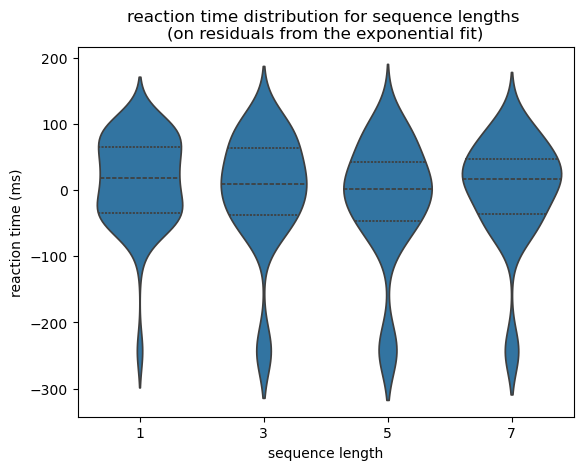

In [124]:
sns.violinplot(x=seq, y=residuals, inner="quartile")

plt.xlabel("sequence length")
plt.ylabel("reaction time (ms)")
plt.title("reaction time distribution for sequence lengths \n(on residuals from the exponential fit)")

plt.show()

## **Events check**

In [125]:
# if task == "MEG" :
#     order = -1
#     error_var = 0
#     for i in range(len(events["event_code"])) : 
#         if events["event_code"][i] == 144 : 
#             num = events["event_code"][i-1]
#             order += 1
#             if num == 129 : 
#                 num = 1
#             elif num == 131 :
#                 num = 3
#             elif num == 133 :
#                 num = 5 
#             elif num == 135 : 
#                 num = 7 
#             else : 
#                 print("error")
            
#             if not num == df_radian[df_radian["Block"]==block]["length of sequence"][order] :
#                 error_var +=1
#                 print("False")

#     if error_var != 0 : 
#         print(f"there is {error_var} errors in the order of sequences between the behavioral data and the MEG triggers")
#     else : 
#         print("There are no errors in the order of sequences between the behavioral data and the MEG triggers")

In [126]:
if task == "ENS" :
    filepaths = glob.glob("/Users/elodiehusson/Desktop/Projet/Comportement ENS/fichiers csv participants/*.csv")
    dfs = [pd.read_csv(f, index_col=2) for f in filepaths]

elif task == "MEG" : 
    filepaths = glob.glob("/Users/elodiehusson/Desktop/Projet/Tâche MEG/Data comportement/data clean behavior MEG/*.csv")
    dfs = [pd.read_csv(f, index_col=0) for f in filepaths]



def all_participants (dfs) :
    
    if task == "ENS" : 
        df_filtered = dfs[dfs["stimulus_rotations"].notna()]
        df_filtered = df_filtered.drop(columns=["rt","target", "time_elapsed", "internal_node_id", "success", "responses", "view_history", "response_rts", "key_press", "confidence", "correct", "trial_type", "stimulus", "failed_tuto1", "failed_tuto2", "failed_tuto3"])
        df_filtered.reset_index(drop=True, inplace=True)
        df_filtered["length of sequence"] = df_filtered["presented_angles"].apply(lambda s: len(s.split(',')) if isinstance(s, str) else 0)
        df_filtered['presented_angles'] = df_filtered['presented_angles'].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
        df_filtered['stimulus_rotations'] = df_filtered['stimulus_rotations'].apply(lambda s: [] if pd.isna(s) else [float(x) for x in s.split(',')])
        df_filtered['score'] = df_filtered['score'].astype(int)
        df_filtered["expected_angles"] = df_filtered.apply(lambda row : [x + y for x,y in zip(row["presented_angles"],row["stimulus_rotations"])], axis=1)

        df_filtered = df_filtered.dropna(subset=["final_angle"])
        df_radian = df_filtered.copy().drop(columns=["presented_angles", "final_angle", "expected_angles", "stimulus_rotations"])
        df_radian['final_angle'] = np.deg2rad(df_filtered['final_angle'])

        df_radian['stimulus_rotations'] = df_filtered['stimulus_rotations'].apply(
            lambda lst: np.deg2rad(np.array(lst, dtype=float)))

        df_radian['presented_angles'] = df_filtered['presented_angles'].apply(
            lambda lst: np.deg2rad(np.array(lst, dtype=float)))

        df_radian['expected_angles'] = df_filtered['expected_angles'].apply(
            lambda lst: np.deg2rad(np.array(lst, dtype=float)))

        df_radian["target"] = df_radian["expected_angles"].apply(CircularMean) 
        df_filtered["target"] = df_radian["target"].apply(np.rad2deg) 

        df_radian["mean_rotation"] = df_radian["stimulus_rotations"].apply(CircularMean) 
        df_radian["error_to_target"] = circular_error(df_radian["final_angle"], df_radian["target"]) 
        df_radian["expected_angles_wo_rot"] = df_radian["presented_angles"].apply(CircularMean)
        df_radian["error_wo_rotation"] = circular_error(df_radian["final_angle"], df_radian["expected_angles_wo_rot"])  
    

    elif task == "MEG" :
        dfs.columns = dfs.columns.str.strip()
        df_filtered = dfs.copy()
        # Exemple: sélection des colonnes rotangle_1 à rotangle_7
        rotangle_cols = [f'rotangle_{i}' for i in range(1, 8)]
        rotation_cols = [f'rotations_{i}' for i in range(1, 8)]
        presangle_cols = [f'presangle_{i}' for i in range(1, 8)]

        df_filtered['presented_angles'] = df_filtered[presangle_cols].apply(lambda row: row.dropna().tolist(), axis=1)
        df_filtered['expected_angles'] = df_filtered[rotangle_cols].apply(lambda row: row.dropna().tolist(), axis=1)
        df_filtered['stimulus_rotations'] = df_filtered[rotation_cols].apply(lambda row: row.dropna().tolist(), axis=1)
        df_filtered["expected_angles_wo_rot"] = df_filtered["presavg"]
        df_filtered["length of sequence"] = df_filtered["Seqlen"]

        df_filtered = df_filtered.drop(columns=rotangle_cols + rotation_cols + presangle_cols)

        df_filtered = df_filtered.drop(columns=["optimal", "presavg", "Seqlen"])
        df_filtered.reset_index(drop=True, inplace=True)
        df_filtered = df_filtered.dropna(subset=["final_angle"])
        df_radian = df_filtered.copy().drop(columns=["presented_angles", "final_angle", "expected_angles", "stimulus_rotations", "GenMean", "target", "expected_angles_wo_rot"])
        df_radian['final_angle'] = np.deg2rad(df_filtered['final_angle'])
        df_radian["target"] = np.deg2rad(df_filtered['target'])
        df_radian["GenMean"] = np.deg2rad(df_filtered['GenMean'])
        df_radian["expected_angles_wo_rot"] = np.deg2rad(df_filtered['expected_angles_wo_rot'])

        df_radian['stimulus_rotations'] = df_filtered['stimulus_rotations'].apply(
            lambda lst: np.deg2rad(np.array(lst, dtype=float)))

        df_radian['presented_angles'] = df_filtered['presented_angles'].apply(
            lambda lst: np.deg2rad(np.array(lst, dtype=float)))

        df_radian['expected_angles'] = df_filtered['expected_angles'].apply(
            lambda lst: np.deg2rad(np.array(lst, dtype=float)))


        df_radian["mean_rotation"] = df_radian["stimulus_rotations"].apply(CircularMean) 
        df_radian["error_to_target"] = circular_error(df_radian["final_angle"], df_radian["target"]) 
        df_radian["expected_angles_wo_rot"] = df_radian["presented_angles"].apply(CircularMean)
        df_radian["error_wo_rotation"] = circular_error(df_radian["final_angle"], df_radian["expected_angles_wo_rot"])  


    return df_radian

def mean_par_sujet (column) : # gives one value per subject
    df_participant = pd.DataFrame()
    for participant in range(len(dfs)):
        df_participant[participant] = all_participants(dfs[participant])[column]
    mean_matrix = df_participant.apply(CircularMean)
    return mean_matrix      

def sd_par_sujet (column) : 
    df_participant = pd.DataFrame()
    for participant in range(len(dfs)):
        df_participant[participant] = all_participants(dfs[participant])[column]
    mean_matrix = df_participant.std()
    return mean_matrix      



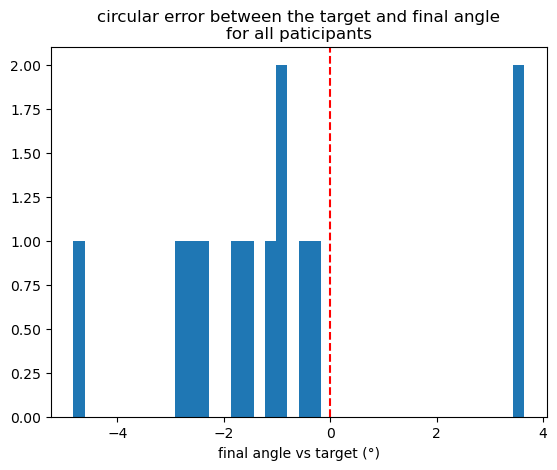

In [127]:
mean_errors_per_participant = []

for participant in range(len(dfs)):
    df_part = all_participants(dfs[participant])
    mean_errors_per_participant.append(df_part["error_to_target"].values)

error_matrix = np.full((len(mean_errors_per_participant), max(len(errors) for errors in mean_errors_per_participant)), np.nan)
for i, errors in enumerate(mean_errors_per_participant):
    error_matrix[i, :len(errors)] = errors 
m_for_plot = np.nanmean(error_matrix, axis=0)

plt.hist(np.rad2deg(mean_par_sujet("error_to_target")), bins=40)
plt.axvline(0, color='red', linestyle='--') 
plt.xlabel("final angle vs target (°)")
plt.title("circular error between the target and final angle\nfor all paticipants")
plt.show()


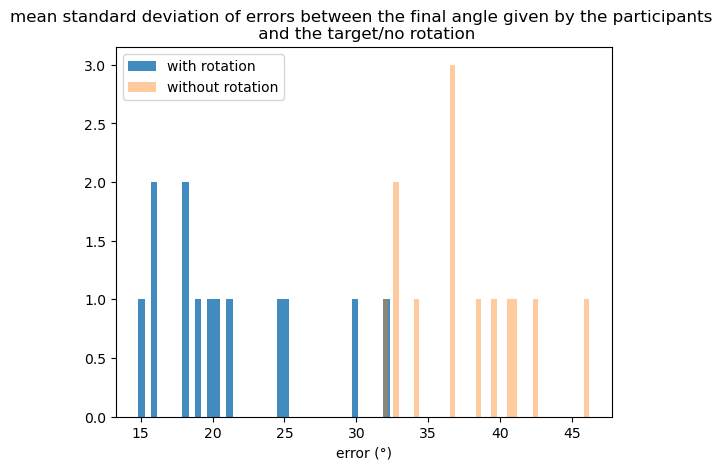

In [128]:
plt.hist(np.rad2deg(sd_par_sujet("error_to_target")), bins=40, label="with rotation", alpha = 0.85)
plt.hist(np.rad2deg(sd_par_sujet("error_wo_rotation")), bins=40, label="without rotation", alpha = 0.4)
plt.xlabel("error (°)")
plt.legend()
plt.title("mean standard deviation of errors between the final angle given by the participants \n and the target/no rotation")
plt.show()


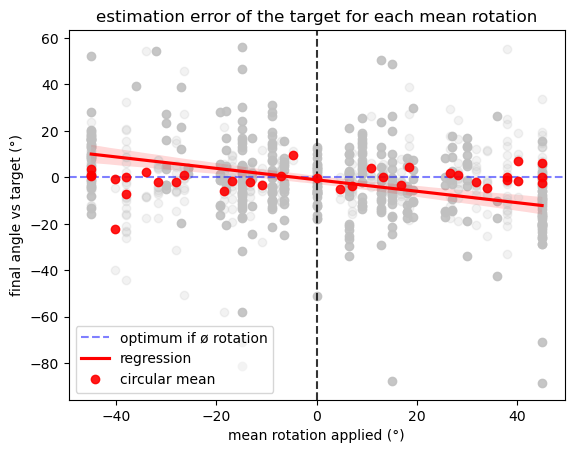

In [129]:
participant_means = []

for participant in range(len(dfs)):
    df_part = all_participants(dfs[participant])
    df_part["error_to_target"] = df_part["error_to_target"].apply(np.rad2deg)
    df_part["mean_rotation"] = df_part["mean_rotation"].apply(np.rad2deg)
    mean_by_rotation = df_part.groupby("mean_rotation")["error_to_target"].mean().reset_index()
    mean_by_rotation["participant"] = participant
    participant_means.append(mean_by_rotation)

df_means_all = pd.concat(participant_means, axis=0)
df_global_mean = df_means_all.groupby("mean_rotation")["error_to_target"].mean().reset_index()

for participant in df_means_all["participant"].unique():
    df_part = df_means_all[df_means_all["participant"] == participant]
    plt.plot(df_part["mean_rotation"], df_part["error_to_target"], 'o', color="silver", alpha=0.2)


plt.axhline(0, color="blue", linestyle="--" , label= "optimum if ø rotation", alpha = 0.5, linewidth =1.5) 
plt.axvline(0, color="black", linestyle="--", alpha = 0.8)   

sns.regplot(x=df_radian["mean_rotation"].apply(np.rad2deg), y=df_radian["error_to_target"].apply(np.rad2deg), color="silver", scatter_kws={'alpha':0.9}, line_kws={"color":"red", "label":"regression"})
plt.plot(df_global_mean["mean_rotation"], df_global_mean["error_to_target"], 'o', color="red", label="circular mean", linewidth = 1, alpha = 0.9)

plt.xlabel("mean rotation applied (°)")
plt.ylabel("final angle vs target (°)")
plt.title("estimation error of the target for each mean rotation")
plt.legend()
plt.show()


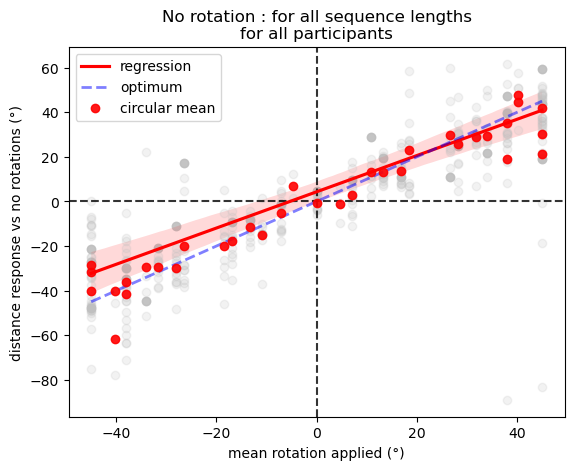

In [130]:
participant_means = []

for participant in range(len(dfs)):
    df_part = all_participants(dfs[participant])
    df_part["error_wo_rotation"] = df_part["error_wo_rotation"].apply(np.rad2deg)
    df_part["mean_rotation"] = df_part["mean_rotation"].apply(np.rad2deg)
    mean_by_rotation = df_part.groupby("mean_rotation")["error_wo_rotation"].mean().reset_index()
    mean_by_rotation["participant"] = participant
    participant_means.append(mean_by_rotation)

df_means_all = pd.concat(participant_means, axis=0)
df_global_mean = df_means_all.groupby("mean_rotation")["error_wo_rotation"].mean().reset_index()

for participant in df_means_all["participant"].unique():
    df_part = df_means_all[df_means_all["participant"] == participant]
    plt.plot(df_part["mean_rotation"], df_part["error_wo_rotation"], 'o', color="silver", alpha=0.2)


plt.axvline(0, color="black", linestyle="--", alpha = 0.8)   
plt.axhline(0, color="black", linestyle="--", alpha = 0.8)   

sns.regplot(x="mean_rotation", y="error_wo_rotation", data=df_part, color="silver", scatter_kws={'alpha':0.9}, line_kws={"color":"red", "label":"regression"})

borne = df_global_mean["mean_rotation"]
plt.plot(np.linspace(min(borne),max(borne),100),np.linspace(min(borne),max(borne),100),"--" , color = "blue",label= "optimum", alpha = 0.5, linewidth =2)
plt.plot(df_global_mean["mean_rotation"], df_global_mean["error_wo_rotation"], 'o', color="red", label="circular mean", linewidth = 1, alpha = 0.9)


plt.xlabel("mean rotation applied (°)")
plt.ylabel("distance response vs no rotations (°)")
plt.title("No rotation : for all sequence lengths\nfor all participants")
plt.legend()
plt.show()


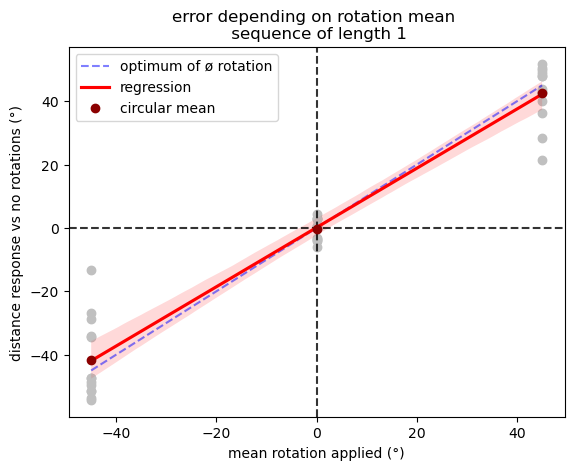

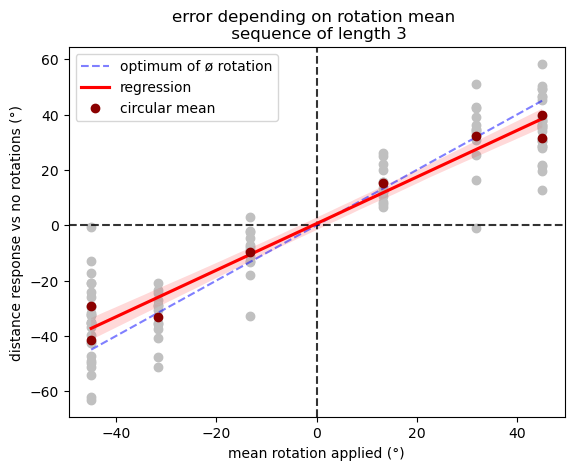

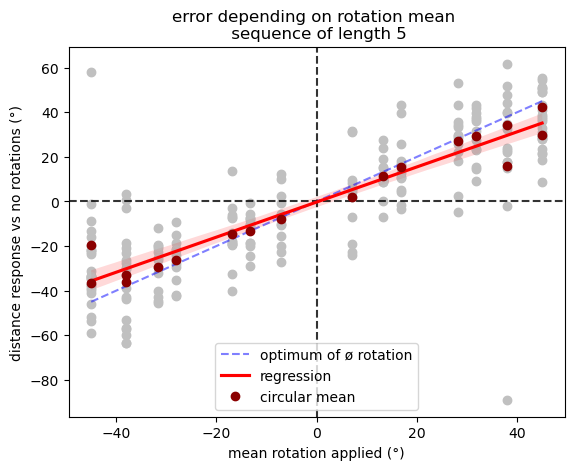

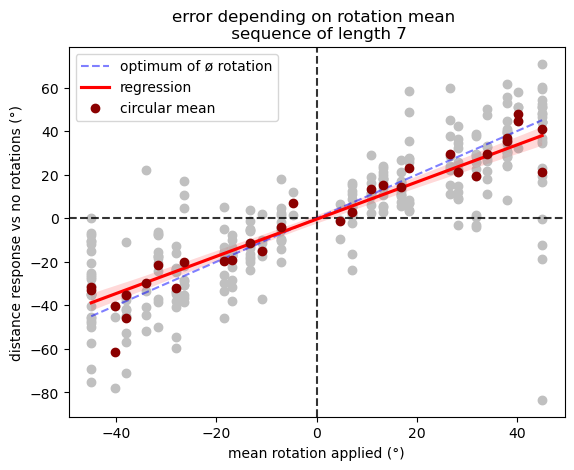

In [131]:
for seqlen in [1,3,5,7] :
    plt.figure()
    participant_means = []

    for participant in range(len(dfs)):
        df_part = all_participants(dfs[participant])
        df_part["error_wo_rotation"] = df_part["error_wo_rotation"].apply(np.rad2deg)
        df_part["mean_rotation"] = df_part["mean_rotation"].apply(np.rad2deg)
        df_part = df_part[df_part["length of sequence"]==seqlen]
        mean_by_rotation = df_part.groupby("mean_rotation")["error_wo_rotation"].mean().reset_index()
        mean_by_rotation["participant"] = participant
        participant_means.append(mean_by_rotation)

    df_means_all = pd.concat(participant_means, axis=0)
    df_global_mean = df_means_all.groupby("mean_rotation")["error_wo_rotation"].mean().reset_index()

    for participant in df_means_all["participant"].unique():
        df_part = df_means_all[df_means_all["participant"] == participant]
        plt.plot(df_part["mean_rotation"], df_part["error_wo_rotation"], 'o', color="silver", alpha=0.2)


    plt.axvline(0, color="black", linestyle="--", alpha = 0.8)   
    plt.axhline(0, color="black", linestyle="--", alpha = 0.8)   


    borne = df_means_all["mean_rotation"]
    plt.plot(np.linspace(min(borne),max(borne),100),np.linspace(min(borne),max(borne),100),"--" , color = "blue",label= "optimum of ø rotation", alpha = 0.5, linewidth =1.5)
    sns.regplot(x="mean_rotation", y="error_wo_rotation", data=df_means_all, color="silver", scatter_kws={'alpha':1}, line_kws={"color":"red", "label":"regression"})
    plt.plot(df_global_mean["mean_rotation"], df_global_mean["error_wo_rotation"], 'o', color="darkred", label="circular mean")

 
    plt.xlabel("mean rotation applied (°)")
    plt.ylabel("distance response vs no rotations (°)")
    plt.title(f"error depending on rotation mean \n sequence of length {seqlen}")
    plt.legend()
    plt.show()


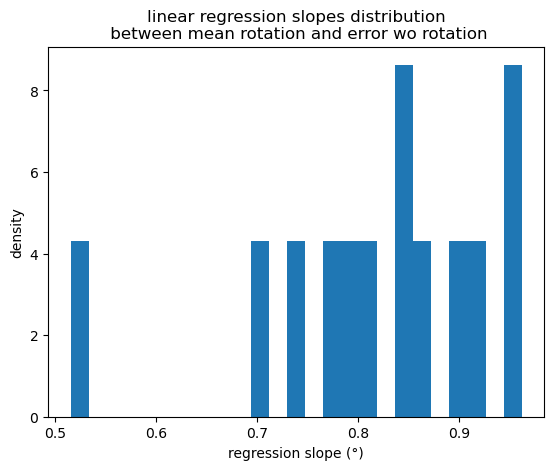

In [132]:
result = []
for participant in range(len(dfs)):
    df_part = all_participants(dfs[participant])
    df_part["error_wo_rotation"] = df_part["error_wo_rotation"].apply(np.rad2deg)
    df_part["mean_rotation"] = df_part["mean_rotation"].apply(np.rad2deg)

    df = df_part[df_part["length of sequence"]!=1]
    x = (df.groupby("mean_rotation")["error_wo_rotation"].apply(np.mean).reset_index().sort_values("mean_rotation"))
    result.append(linregress(df["mean_rotation"], df["error_wo_rotation"]).slope)
    
plt.hist(result, bins=25, density = True)
plt.title("linear regression slopes distribution\n between mean rotation and error wo rotation")
plt.xlabel("regression slope (°)")
plt.ylabel("density")
# plt.savefig("/Users/elodiehusson/Desktop/Projet/Sanity check comportement code/distribution slopes.pdf")
plt.show()

moyenne de la valeur absolue de l'erreur à la target

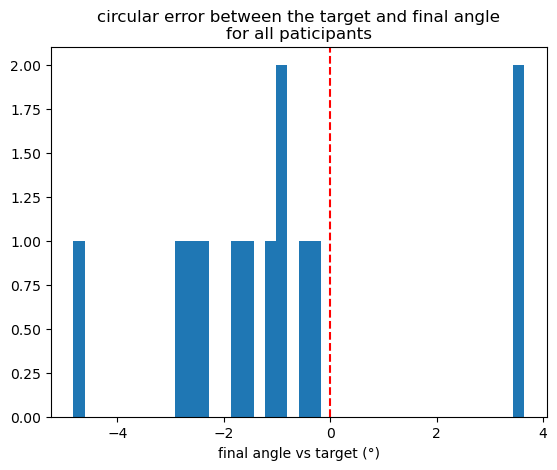

In [133]:
mean_errors_per_participant = []
for participant in range(len(dfs)):
    df_part = all_participants(dfs[participant])
    errors = df_part["error_to_target"].apply(np.abs).values
    mean_errors_per_participant.append(errors)
    
len(mean_errors_per_participant)
    
    

error_matrix = np.full((len(mean_errors_per_participant), max(len(errors) for errors in mean_errors_per_participant)), np.nan)
for i, errors in enumerate(mean_errors_per_participant):
    error_matrix[i, :len(errors)] = errors 
m_for_plot = np.nanmean(error_matrix, axis=0)

plt.hist(np.rad2deg(mean_par_sujet("error_to_target")), bins=40)
plt.axvline(0, color='red', linestyle='--') 
plt.xlabel("final angle vs target (°)")
plt.title("circular error between the target and final angle\nfor all paticipants")
plt.show()
